# Level 3 · Time Series Forecasting — lab notebook
**BIM41 Advanced Predictive Analytics · Dr. Sridevi Tandley · Bharathidasan Institute of Management**

This notebook backs every code slide in the Level 3 deck. Run it top to bottom (Runtime → Run all on Google Colab).

| Part | What you do | Deck slide |
|---|---|---|
| 1 | Load the retail sales data, fill gaps, plot it | Act 1 |
| 2 | Decompose: trend, seasonality, noise | Act 1 |
| 3 | Test stationarity (ADF), difference, read ACF/PACF | Act 2 |
| 4 | The seasonal-index worked example (corrected) | Act 2 |
| 5 | SARIMAX with exogenous variables + prediction intervals | Act 3 |
| 6 | Holt-Winters exponential smoothing | Act 3 |
| 7 | Prophet with a regressor | Act 3 |
| 8 | Rolling-origin cross-validation: who really wins? | Act 5 |
| 9 | Ensemble, uncertainty, CRPS and Monte Carlo | Act 5 |
| 10 | Structural model (BSTS idea) and the course Kalman example | Act 4 |
| 11 | LSTM and GRU for daily energy demand | Act 4 |
| 12 | Optuna tuning · VAR · the random-walk trap | Act 4–5 |

**All data here is synthetic** (fixed random seeds), generated in Part 1 so the notebook runs anywhere without downloads.

In [1]:
# Run this once if a library is missing (Google Colab has most of them). Tested November 2026.
# %pip install -q "pandas<3" statsmodels prophet tensorflow optuna properscoring scikit-learn
import warnings
warnings.filterwarnings("ignore", category=UserWarning)
warnings.filterwarnings("ignore", category=FutureWarning)   # library deprecation notices
import os
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"                     # quieter TensorFlow start-up
import numpy as np, pandas as pd, matplotlib.pyplot as plt
pd.set_option("display.precision", 3)
plt.rcParams["figure.figsize"] = (11, 4)
print("pandas", pd.__version__, "| numpy", np.__version__)

pandas 2.3.3 | numpy 2.5.4


## Part 1 · The data
A retail chain's **monthly sales (₹ lakh)**, 2016–2025. Like the course deck's SARIMAX example, sales follow a festive season
(the `festive` index, 0–1, peaking October–December) and respond to **ad spend** (₹ lakh). Two more drivers:
* `diwali` = 1 in the Diwali month, which moves between **October and November** from year to year, so a fixed monthly season cannot learn it.
  Months used here: Oct in 2016, 2017, 2019, 2022, 2024, 2025 and Nov in 2018, 2020, 2021, 2023 (check an official calendar if you reuse this).
* `lockdown` = 1 for April–May 2020.

Three sales months are missing on purpose, as real data often is.

In [2]:
def make_retail(seed=7):
    rng = np.random.default_rng(seed)
    idx = pd.date_range("2016-01-01", "2025-12-01", freq="MS")
    t = np.arange(len(idx))
    festive_by_month = {1: .2, 2: .1, 3: .2, 4: .3, 5: .2, 6: .2, 7: .3, 8: .5, 9: .4, 10: .9, 11: 1.0, 12: .8}
    festive = idx.month.map(festive_by_month).to_numpy()
    diwali_month = {2016: 10, 2017: 10, 2018: 11, 2019: 10, 2020: 11, 2021: 11, 2022: 10, 2023: 11, 2024: 10, 2025: 10}
    diwali = np.array([int(d.month == diwali_month[d.year]) for d in idx])
    lockdown = ((idx >= "2020-04-01") & (idx <= "2020-05-01")).astype(int)
    ad = np.round(10 + 0.08 * t + 8 * festive + rng.normal(0, 1, len(t)), 1)
    level = 200 + 2.0 * t + np.cumsum(rng.normal(0, 2.5, len(t)))      # trend that wanders a little
    sales = level * (1 + 0.30 * festive) * (1 + 0.15 * diwali) + 4 * ad + rng.normal(0, 10, len(t))
    sales = np.where(lockdown == 1, sales * 0.55, sales)
    df = pd.DataFrame({"sales": np.round(sales, 1), "ad_spend": ad, "festive": festive,
                       "diwali": diwali, "lockdown": lockdown}, index=idx)
    df.index.name = "month"
    df.loc[["2019-07-01", "2022-02-01", "2023-09-01"], "sales"] = np.nan   # gaps to impute
    return df

raw = make_retail()
raw.to_csv("retail_sales_monthly.csv")
print(raw.shape, "| missing sales months:", raw["sales"].isna().sum())
raw.head()

(120, 5) | missing sales months: 3


,sales,ad_spend,festive,diwali,lockdown
month,,,,,
2016-01-01,254.0,11.6,0.2,0,0
2016-02-01,259.0,11.2,0.1,0,0
2016-03-01,259.8,11.5,0.2,0,0
2016-04-01,265.0,11.7,0.3,0,0
2016-05-01,253.6,11.5,0.2,0,0


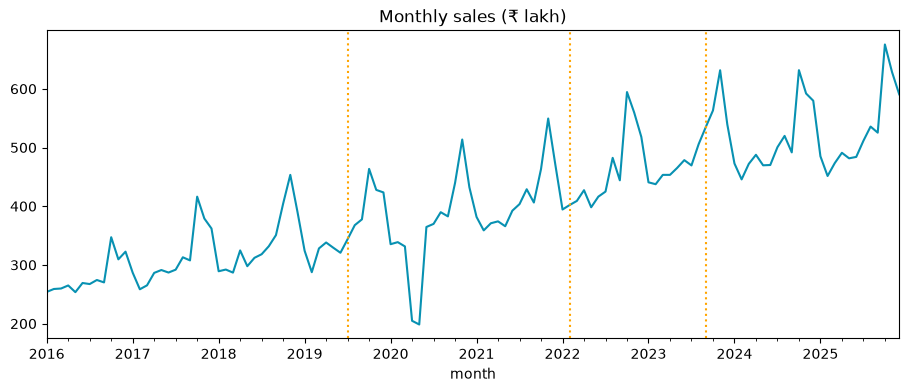

In [3]:
# Fill the gaps: time-based interpolation keeps the shape of the series
df = raw.copy()
df["sales"] = df["sales"].interpolate(method="time")
ax = df["sales"].plot(title="Monthly sales (₹ lakh)", color="#0891b2")
raw["sales"][raw["sales"].isna()].index.map(lambda d: ax.axvline(d, color="orange", ls=":"))
plt.show()

## Part 2 · Decompose: trend + seasonality + noise

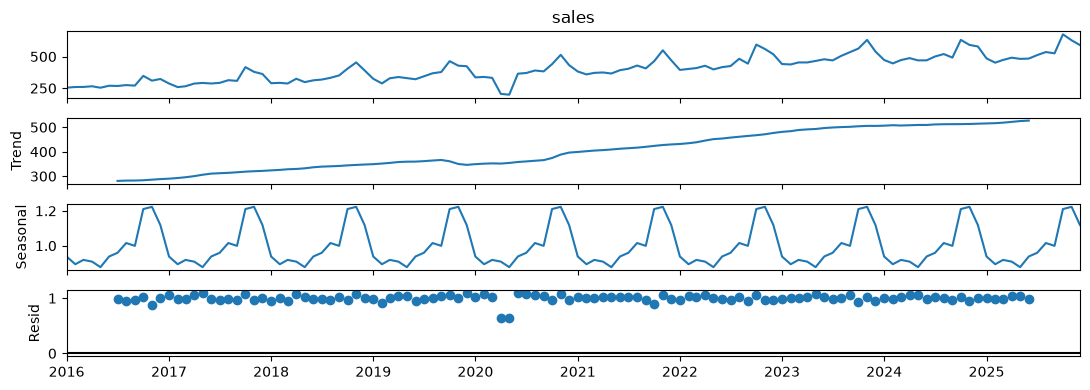

Peak-to-trough swing by year:
 month
2016     94.0
2017    158.0
2018    166.0
2019    176.0
2020    315.0
2021    191.0
2022    200.0
2023    194.0
2024    186.0
2025    224.0


In [4]:
from statsmodels.tsa.seasonal import seasonal_decompose, STL

dec_add = seasonal_decompose(df["sales"], model="additive", period=12)
dec_mul = seasonal_decompose(df["sales"], model="multiplicative", period=12)
dec_mul.plot(); plt.show()

# Do the seasonal swings grow with the level? Compare the festive-peak size early vs late
peak = df["sales"].groupby(df.index.year).agg(lambda s: s.max() - s.min())
print("Peak-to-trough swing by year:\n", peak.round(0).to_string())

In [5]:
# STL: robust, lets seasonality evolve over time
stl = STL(df["sales"], period=12, robust=True).fit()
strength_season = max(0, 1 - stl.resid.var() / (stl.seasonal + stl.resid).var())
strength_trend = max(0, 1 - stl.resid.var() / (stl.trend + stl.resid).var())
print(f"Seasonal strength {strength_season:.2f} | trend strength {strength_trend:.2f}  (1 = very strong)")

Seasonal strength 0.80 | trend strength 0.93  (1 = very strong)


## Part 3 · Stationarity: ADF test, differencing, ACF and PACF
ADF null hypothesis (H₀): the series has a unit root, i.e. it is **non-stationary**. p < 0.05 → reject H₀ → treat as stationary.

In [6]:
from statsmodels.tsa.stattools import adfuller

def adf_report(series, name):
    stat, p, *_ = adfuller(series.dropna())
    verdict = "stationary" if p < 0.05 else "NOT stationary"
    print(f"{name:<32} ADF = {stat:7.2f}   p = {p:.3f}   → {verdict}")

y = df["sales"]
adf_report(y, "Sales (level)")
adf_report(np.log(y), "log(sales)")
adf_report(np.log(y).diff(), "Δ log(sales)  (d = 1)")
adf_report(np.log(y).diff().diff(12), "Δ₁₂ Δ log(sales)  (d = 1, D = 1)")

Sales (level)                    ADF =   -0.27   p = 0.929   → NOT stationary
log(sales)                       ADF =   -0.81   p = 0.815   → NOT stationary
Δ log(sales)  (d = 1)            ADF =   -8.87   p = 0.000   → stationary
Δ₁₂ Δ log(sales)  (d = 1, D = 1) ADF =   -4.22   p = 0.001   → stationary


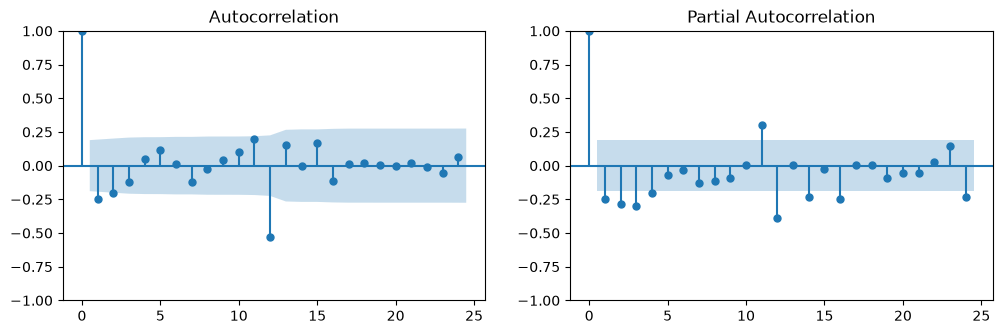

In [7]:
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
stationary = np.log(y).diff().diff(12).dropna()
fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))
plot_acf(stationary, lags=24, ax=ax[0]); plot_pacf(stationary, lags=24, ax=ax[1], method="ywm")
plt.show()

## Part 4 · Seasonal index: the worked example from the course deck (corrected)
The course deck divides by an overall average of 330.83, but the twelve sales figures sum to 3,670, so the average is **305.83**.
Recomputing gives the corrected indices below. Spot-the-error is a game in the Level 3 deck.

In [8]:
q = pd.DataFrame({"year": [2022]*4 + [2023]*4 + [2024]*4, "quarter": ["Q1", "Q2", "Q3", "Q4"] * 3,
                  "sales": [200, 250, 400, 300, 220, 260, 420, 320, 240, 270, 450, 340]})
overall = q["sales"].mean()
idx_q = (q.groupby("quarter")["sales"].mean() / overall).round(3)
q["deseasonalised"] = (q["sales"] / q["quarter"].map(idx_q)).round(0)
print(f"Overall average = {overall:.2f}")
print("Seasonal index:", idx_q.to_dict(), "| sum =", round(idx_q.sum(), 3), "(should be 4)")
q

Overall average = 305.83
Seasonal index: {'Q1': 0.719, 'Q2': 0.85, 'Q3': 1.384, 'Q4': 1.046} | sum = 3.999 (should be 4)


,year,quarter,sales,deseasonalised
0,2022,Q1,200,278.0
1,2022,Q2,250,294.0
2,2022,Q3,400,289.0
3,2022,Q4,300,287.0
4,2023,Q1,220,306.0
5,2023,Q2,260,306.0
6,2023,Q3,420,303.0
7,2023,Q4,320,306.0
8,2024,Q1,240,334.0
9,2024,Q2,270,318.0


## Part 5 · SARIMAX with exogenous variables
Train on 2016–2024, test on 2025. **Exogenous variables must be known for the forecast period** (planned ad spend, the festive calendar).

In [9]:
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.stats.diagnostic import acorr_ljungbox

exog_cols = ["ad_spend", "diwali", "lockdown"]     # festive is left to the seasonal terms
train, test = df.loc[:"2024-12-01"], df.loc["2025-01-01":]
sarimax = SARIMAX(np.log(train["sales"]), exog=train[exog_cols],
                  order=(1, 1, 1), seasonal_order=(0, 1, 1, 12)).fit(disp=False, maxiter=500)
print(sarimax.summary().tables[1])
fc = sarimax.get_forecast(steps=len(test), exog=test[exog_cols])
pred = np.exp(fc.predicted_mean)
ci = np.exp(fc.conf_int(alpha=0.05))            # 95% prediction interval
mape = lambda a, f: float(np.mean(np.abs((np.asarray(a) - np.asarray(f)) / np.asarray(a))) * 100)
print(f"SARIMAX test MAPE 2025: {mape(test['sales'], pred):.1f}%   AIC {sarimax.aic:.1f}")
print(acorr_ljungbox(sarimax.resid[13:], lags=[12]))   # p > 0.05: residuals look like white noise

                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ad_spend       0.0054      0.004      1.297      0.195      -0.003       0.014
diwali         0.1145      0.018      6.232      0.000       0.078       0.150
lockdown      -0.5593      0.065     -8.607      0.000      -0.687      -0.432
ar.L1          0.1251      0.172      0.729      0.466      -0.211       0.461
ma.L1         -0.7857      0.114     -6.885      0.000      -1.009      -0.562
ma.S.L12      -0.9656      1.056     -0.915      0.360      -3.034       1.103
sigma2         0.0011      0.001      0.974      0.330      -0.001       0.003
SARIMAX test MAPE 2025: 3.2%   AIC -342.4
    lb_stat  lb_pvalue
12   20.311      0.061


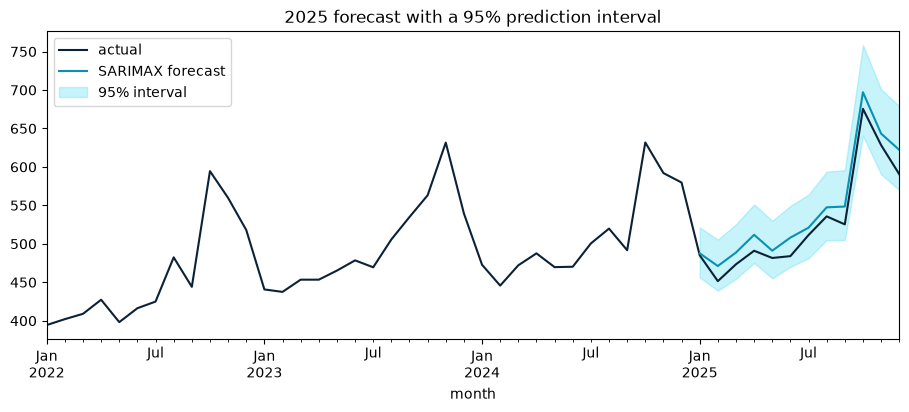

In [10]:
ax = df["sales"].loc["2022":].plot(label="actual", color="#0B2236")
pred.plot(ax=ax, label="SARIMAX forecast", color="#0891b2")
ax.fill_between(ci.index, ci.iloc[:, 0], ci.iloc[:, 1], color="#22d3ee", alpha=0.25, label="95% interval")
ax.legend(); ax.set_title("2025 forecast with a 95% prediction interval"); plt.show()

## Part 6 · Holt-Winters exponential smoothing (level + trend + season)

In [11]:
from statsmodels.tsa.holtwinters import ExponentialSmoothing

hw = ExponentialSmoothing(train["sales"], trend="add", seasonal="mul", seasonal_periods=12).fit()
hw_pred = hw.forecast(len(test))
print({k: round(v, 3) for k, v in hw.params.items() if k in ("smoothing_level", "smoothing_trend", "smoothing_seasonal")})
print(f"Holt-Winters (additive trend, multiplicative season) MAPE 2025: {mape(test['sales'], hw_pred):.1f}%")
hw_add = ExponentialSmoothing(train["sales"], trend="add", seasonal="add", seasonal_periods=12).fit()
print(f"Holt-Winters (all additive) MAPE 2025: {mape(test['sales'], hw_add.forecast(len(test))):.1f}%")

{'smoothing_level': np.float64(0.152), 'smoothing_trend': np.float64(0.0), 'smoothing_seasonal': np.float64(0.0)}
Holt-Winters (additive trend, multiplicative season) MAPE 2025: 3.0%
Holt-Winters (all additive) MAPE 2025: 4.0%


## Part 7 · Prophet with a regressor
Prophet expects two columns, `ds` (date) and `y` (value). It tolerates missing `y` values, so we pass the **raw** series with its gaps.

In [12]:
import logging
logging.getLogger("cmdstanpy").setLevel(logging.WARNING)
from prophet import Prophet

p_train = raw.loc[:"2024-12-01"].reset_index().rename(columns={"month": "ds", "sales": "y"})
prophet = Prophet(yearly_seasonality=True, weekly_seasonality=False, daily_seasonality=False,
                  seasonality_mode="multiplicative", interval_width=0.95)
for col in exog_cols:
    prophet.add_regressor(col)
prophet.fit(p_train)
future = df.reset_index().rename(columns={"month": "ds"})[["ds"] + exog_cols]
p_fc = prophet.predict(future).set_index("ds")
p_pred = p_fc.loc["2025-01-01":, "yhat"]
print(f"Prophet MAPE 2025: {mape(test['sales'], p_pred):.1f}%  (rows with missing y in training: {p_train['y'].isna().sum()})")

Prophet MAPE 2025: 2.0%  (rows with missing y in training: 3)


## Part 8 · Rolling-origin cross-validation: never shuffle time
Four folds, each forecasting the next 6 months from everything before it. We compare a **seasonal-naive baseline** (same month last year) with Holt-Winters and SARIMAX.

In [13]:
from sklearn.model_selection import TimeSeriesSplit

tscv = TimeSeriesSplit(n_splits=4, test_size=6)
scores = {"Seasonal naive": [], "Holt-Winters": [], "SARIMAX": []}
for k, (tr_idx, te_idx) in enumerate(tscv.split(df)):
    tr, te = df.iloc[tr_idx], df.iloc[te_idx]
    snaive = df["sales"].shift(12).iloc[te_idx]
    hw_k = ExponentialSmoothing(tr["sales"], trend="add", seasonal="mul", seasonal_periods=12).fit().forecast(len(te))
    sx_k = SARIMAX(np.log(tr["sales"]), exog=tr[exog_cols], order=(1, 1, 1),
                   seasonal_order=(0, 1, 1, 12)).fit(disp=False, maxiter=500)
    sx_pred = np.exp(sx_k.get_forecast(len(te), exog=te[exog_cols]).predicted_mean)
    for name, f in [("Seasonal naive", snaive), ("Holt-Winters", hw_k), ("SARIMAX", sx_pred)]:
        scores[name].append(mape(te["sales"], f))
    print(f"fold {k+1}: train to {tr.index[-1]:%Y-%m}, test {te.index[0]:%Y-%m}…{te.index[-1]:%Y-%m}")
cv = pd.DataFrame(scores, index=[f"fold {i+1}" for i in range(4)])
cv.loc["mean"] = cv.mean()
cv.round(1)

fold 1: train to 2023-12, test 2024-01…2024-06


fold 2: train to 2024-06, test 2024-07…2024-12


fold 3: train to 2024-12, test 2025-01…2025-06


fold 4: train to 2025-06, test 2025-07…2025-12


,Seasonal naive,Holt-Winters,SARIMAX
fold 1,3.7,2.8,2.4
fold 2,7.0,4.3,4.8
fold 3,1.7,2.6,3.2
fold 4,4.3,2.6,1.1
mean,4.2,3.1,2.9


## Part 9 · Ensemble, uncertainty, CRPS and Monte Carlo

In [14]:
ens = (pred.values + hw_pred.values + p_pred.values) / 3
board = pd.Series({"SARIMAX": mape(test["sales"], pred), "Holt-Winters": mape(test["sales"], hw_pred),
                   "Prophet": mape(test["sales"], p_pred), "Ensemble (average)": mape(test["sales"], ens)})
print("2025 test MAPE (%):\n", board.round(1).sort_values().to_string())

2025 test MAPE (%):
 Prophet               2.0
Ensemble (average)    2.4
Holt-Winters          3.0
SARIMAX               3.2


In [15]:
import properscoring as ps

# CRPS rewards a forecast distribution that is both sharp and well placed (lower is better)
sd_log = np.sqrt(fc.var_pred_mean)                          # SARIMAX forecast s.d. on the log scale
crps = ps.crps_gaussian(np.log(test["sales"]).values, mu=fc.predicted_mean.values, sig=sd_log.values)
inside = ((test["sales"] >= ci.iloc[:, 0]) & (test["sales"] <= ci.iloc[:, 1])).mean()
print(f"Mean CRPS (log scale): {crps.mean():.4f} | share of 2025 months inside the 95% interval: {inside:.0%}")

Mean CRPS (log scale): 0.0201 | share of 2025 months inside the 95% interval: 100%


2025 annual sales: median ₹6,543 lakh, 90% range ₹6,260–6,797 lakh | actual ₹6,334 lakh


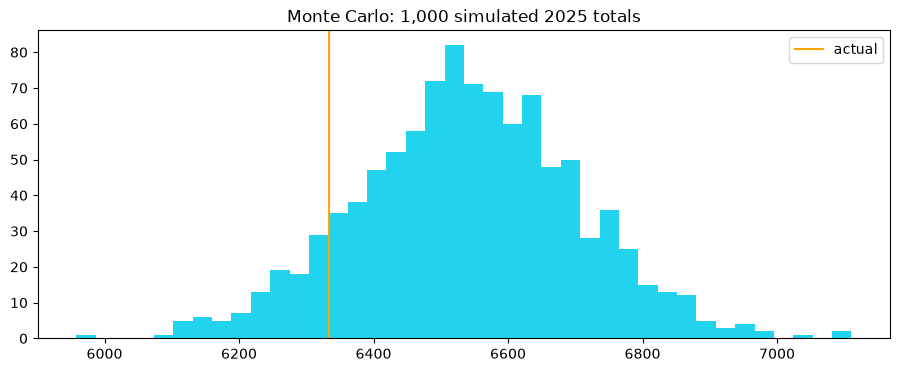

In [16]:
# Monte Carlo: simulate 1,000 possible 2025 paths and read the annual total as a range, not a point
np.random.seed(1)
sims = sarimax.simulate(nsimulations=len(test), repetitions=1000, anchor="end", exog=test[exog_cols])
annual = np.exp(np.asarray(sims)).reshape(len(test), -1).sum(axis=0)
lo, mid, hi = np.percentile(annual, [5, 50, 95])
print(f"2025 annual sales: median ₹{mid:,.0f} lakh, 90% range ₹{lo:,.0f}–{hi:,.0f} lakh | actual ₹{test['sales'].sum():,.0f} lakh")
plt.hist(annual, bins=40, color="#22d3ee"); plt.axvline(test["sales"].sum(), color="orange", label="actual")
plt.title("Monte Carlo: 1,000 simulated 2025 totals"); plt.legend(); plt.show()

## Part 10 · Structural time series (the BSTS idea)
BSTS models a series as **components** (level, trend, season, regression) in state-space form, updated by the **Kalman filter**.
Python's `UnobservedComponents` fits the same structural model by maximum likelihood (it is not Bayesian). For full BSTS with spike-and-slab
variable selection, use R's `bsts` package or TensorFlow Probability's `sts` module.

In [17]:
from statsmodels.tsa.statespace.structural import UnobservedComponents

ucm = UnobservedComponents(np.log(train["sales"]), level="local linear trend", freq_seasonal=[{"period": 12, "harmonics": 4}],
                           exog=train[exog_cols]).fit(disp=False, maxiter=1000)
ucm_pred = np.exp(ucm.get_forecast(len(test), exog=test[exog_cols]).predicted_mean)
print(f"Structural (UCM) MAPE 2025: {mape(test['sales'], ucm_pred):.1f}%")

Structural (UCM) MAPE 2025: 3.0%


In [18]:
# The course deck's 5-month Kalman example: local level, prior N(19, 1), noise variances 1 (observation) and 0.25 (level)
y5 = [20, 21, 19, 22, 24]; m, P, Q, R = 19.0, 1.0, 0.25, 1.0
rows = []
for t, obs in enumerate(y5, 1):
    P = P + Q                    # predict: the level may have drifted
    K = P / (P + R)              # Kalman gain: how much to trust the new observation
    m = m + K * (obs - m); P = (1 - K) * P
    rows.append((t, obs, round(m, 2), round(np.sqrt(P), 2)))
sd6 = np.sqrt(P + Q + R)
print(pd.DataFrame(rows, columns=["month", "sales", "posterior mean", "posterior sd"]).to_string(index=False))
print(f"Month 6 forecast: {m:.2f}, 95% range ({m - 1.96*sd6:.1f}, {m + 1.96*sd6:.1f})")

 month  sales  posterior mean  posterior sd
     1     20           19.56          0.75
     2     21           20.20          0.67
     3     19           19.71          0.64
     4     22           20.62          0.63
     5     24           21.95          0.63
Month 6 forecast: 21.95, 95% range (19.4, 24.5)


## Part 11 · Deep learning: LSTM vs GRU for daily energy demand
Hands-on from the syllabus: predict energy demand. Daily demand (MWh) for 2022–2025 with a summer peak and a Sunday dip.
We forecast **one day ahead** from the previous 28 days and compare with a seasonal-naive baseline (same weekday last week).

In [19]:
def make_energy(seed=11):
    rng = np.random.default_rng(seed)
    idx = pd.date_range("2022-01-01", "2025-12-31", freq="D")
    t = np.arange(len(idx))
    temp = 27 + 7 * np.sin(2 * np.pi * (idx.day_of_year - 45) / 365.25) + rng.normal(0, 1.5, len(t))
    demand = 500 + 0.05 * t + 9 * (temp - 27) - 40 * (idx.day_of_week == 6) + rng.normal(0, 12, len(t))
    return pd.DataFrame({"demand_mwh": demand.round(1), "temp_c": temp.round(1)}, index=pd.Index(idx, name="date"))

energy = make_energy(); energy.to_csv("energy_demand_daily.csv")
series = energy["demand_mwh"].to_numpy(dtype="float32")
WINDOW, TEST_DAYS = 28, 90
mu, sd = series[:-TEST_DAYS].mean(), series[:-TEST_DAYS].std()
z = (series - mu) / sd                                         # scale with training statistics only
X = np.stack([z[i - WINDOW:i] for i in range(WINDOW, len(z))])[..., None]
Y = z[WINDOW:]
X_tr, Y_tr, X_te, Y_te = X[:-TEST_DAYS], Y[:-TEST_DAYS], X[-TEST_DAYS:], Y[-TEST_DAYS:]
print(X_tr.shape, X_te.shape)

(1343, 28, 1) (90, 28, 1)


In [20]:
import tensorflow as tf
from tensorflow import keras
tf.keras.utils.set_random_seed(42)

def make_rnn(cell):
    model = keras.Sequential([keras.Input(shape=(WINDOW, 1)), cell(32), keras.layers.Dense(1)])
    model.compile(optimizer="adam", loss="mse")
    return model

results = {}
for name, cell in [("LSTM", keras.layers.LSTM), ("GRU", keras.layers.GRU)]:
    net = make_rnn(cell)
    net.fit(X_tr, Y_tr, epochs=30, batch_size=32, validation_split=0.1, verbose=0,
            callbacks=[keras.callbacks.EarlyStopping(patience=4, restore_best_weights=True)])
    pred_mwh = net.predict(X_te, verbose=0).ravel() * sd + mu
    results[name] = (pred_mwh, net.count_params())

actual = series[-TEST_DAYS:]
naive7 = series[-TEST_DAYS - 7:-7]
mae = lambda a, f: float(np.mean(np.abs(a - f)))
print(f"Seasonal naive (same weekday last week) MAE: {mae(actual, naive7):.1f} MWh")
for name, (p, n_par) in results.items():
    print(f"{name:<4} MAE: {mae(actual, p):.1f} MWh   parameters: {n_par:,}")

Seasonal naive (same weekday last week) MAE: 21.1 MWh
LSTM MAE: 18.8 MWh   parameters: 4,385
GRU  MAE: 19.0 MWh   parameters: 3,393


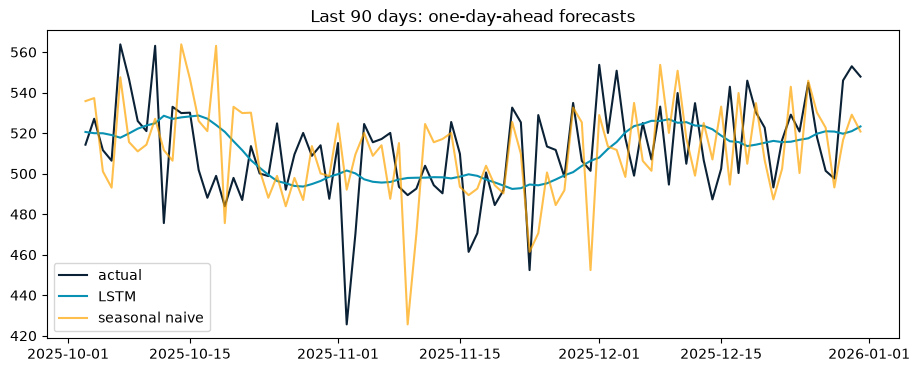

In [21]:
plt.plot(energy.index[-TEST_DAYS:], actual, label="actual", color="#0B2236")
plt.plot(energy.index[-TEST_DAYS:], results["LSTM"][0], label="LSTM", color="#0891b2")
plt.plot(energy.index[-TEST_DAYS:], naive7, label="seasonal naive", color="orange", alpha=.7)
plt.legend(); plt.title("Last 90 days: one-day-ahead forecasts"); plt.show()

## Part 12 · Tuning with Optuna, a multivariate VAR, and the random-walk trap

In [22]:
import optuna
optuna.logging.set_verbosity(optuna.logging.WARNING)

valid = train.loc["2024-01-01":]; fit_part = train.loc[:"2023-12-01"]
def objective(trial):
    order = (trial.suggest_int("p", 0, 2), 1, trial.suggest_int("q", 0, 2))
    seas = (trial.suggest_int("P", 0, 1), 1, trial.suggest_int("Q", 0, 1), 12)
    res = SARIMAX(np.log(fit_part["sales"]), exog=fit_part[exog_cols], order=order, seasonal_order=seas).fit(disp=False, maxiter=500)
    return mape(valid["sales"], np.exp(res.get_forecast(len(valid), exog=valid[exog_cols]).predicted_mean))

study = optuna.create_study(direction="minimize", sampler=optuna.samplers.TPESampler(seed=42))
study.optimize(objective, n_trials=15)
print("Best orders on the 2024 validation year:", study.best_params, f"→ MAPE {study.best_value:.1f}%")

Best orders on the 2024 validation year: {'p': 2, 'q': 0, 'P': 0, 'Q': 1} → MAPE 2.6%


In [23]:
from statsmodels.tsa.api import VAR

# Multivariate: do sales and ad spend move each other? Model the differenced pair jointly
pair = np.log(df[["sales", "ad_spend"]]).diff().dropna()
var = VAR(pair).fit(maxlags=6, ic="aic")
print("Lag order chosen by AIC:", var.k_ar)
print(var.test_causality("sales", ["ad_spend"], kind="f").summary())

Lag order chosen by AIC: 5
Granger causality F-test. H_0: ad_spend does not Granger-cause sales. Conclusion: fail to reject H_0 at 5% significance level.
Test statistic Critical value p-value         df        
--------------------------------------------------------
         2.118          2.258   0.065 (5, np.int64(206))
--------------------------------------------------------


In [24]:
# The random-walk trap: daily stock prices. Can ARIMA beat "tomorrow = today"?
from statsmodels.tsa.arima.model import ARIMA
rng = np.random.default_rng(3)
price = pd.Series(1500 * np.exp(np.cumsum(rng.normal(0.0003, 0.015, 750))),
                  index=pd.bdate_range("2023-01-02", periods=750))
hist, fut = price.iloc[:-30], price.iloc[-30:]
arima = ARIMA(np.log(hist), order=(1, 1, 1)).fit()
arima_pred = np.exp(arima.forecast(30)).values
naive = np.repeat(hist.iloc[-1], 30)
print(f"30-day MAE  naive: ₹{mae(fut.values, naive):.1f}   ARIMA(1,1,1): ₹{mae(fut.values, arima_pred):.1f}")
print("On a random walk the naive forecast is hard to beat: the honest output is a wide interval, not a confident line.")

30-day MAE  naive: ₹109.6   ARIMA(1,1,1): ₹109.5
On a random walk the naive forecast is hard to beat: the honest output is a wide interval, not a confident line.


### What to take away
* Always report a **simple baseline** (seasonal naive) next to any complex model.
* Validate with **rolling origins**; never shuffle time.
* Ship forecasts with **intervals**, and check how often reality lands inside them.
* Libraries for scale and automation that the course mentions: **Darts** (unified API incl. deep models), **PyCaret** and **AutoTS** (AutoML).
  They change quickly — check their current docs before using them.